# Practice 3: Latent Space Classification

**Developed by:** Antonio Vila Leis and David Florez Mazuera

## Introduction

This project explores the use of unsupervised learning for feature extraction via an Autoencoder and subsequently leveraging those learned representations to train a classifier with limited labeled data.

The dataset used in this assignment is STL-10. It consists of 96x96 pixel color images belonging to 10 classes (such as airplanes, birds, cars, and cats). It provides a small subset of labeled images (5,000 for training, 800 per class for testing) alongside a huge pool of 100000 unlabeled images.

The project development is structured into five main phases:

1. **Setup and Preprocessing:** Loading the STL-10 dataset partitions (labeled and unlabeled) and applying appropriate preprocessing process.

2. **Baseline:** Evaluation of the performance obtained by a standard supervised CNN model (developed in Practice 1) trained solely on the labeled dataset. This establishes the benchmark to evaluate the effectiveness of the autoencoder-based approach.

3. **Unsupervised Training (Autoencoder):** Design and training of a Convolutional Autoencoder using the 100000 unlabeled images. The goal is to force the network to learn a compact and meaningful latent representation of the input space by learning to reconstruct the original images.

4. **Latent Space Classification:** Construction of a classifier on top of the frozen encoder trained in the previous step. The model will operate exclusively in the latent space, using the labeled images for training. This section also includes a thorough analysis of different regularization techniques to mitigate overfitting given the limited labeled data.

5. **Fine-Tuning:** An advanced refinement phase to explore techniques and parameters that allow for improvement of previous results.

## 1. Setup and Preprocessing

### Import Libraries and Setup

In [47]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
    # Reduces the number of warnings
    
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds

# Configure matplotlib for inline plotting
%matplotlib inline

# Set random seeds for reproducibility
SEED = 123
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("="*60)
print("STL-10 Dataset CNN Classifier")
print("="*60)
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("="*60)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
# To avoid stalling due to memory problems

STL-10 Dataset CNN Classifier
TensorFlow version: 2.20.0
Keras version: 3.12.0
GPU Available: False


### Configuration parameters

In [48]:
IMG_SIZE = 96  # STL-10 native size
UNS_BATCH_SIZE = 128
EPOCHS = 200
NUM_CLASSES = 10  # airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck
INITIAL_LR = 0.001

# Class names for visualization
CLASS_NAMES = ['airplane', 'bird', 'car', 'cat', 'deer', 
               'dog', 'horse', 'monkey', 'ship', 'truck']

print(f"Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch Size: {UNS_BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Initial Learning Rate: {INITIAL_LR}")
print(f"\nClasses: {', '.join(CLASS_NAMES)}")

Image Size: 96x96
Batch Size: 128
Epochs: 200
Number of Classes: 10
Initial Learning Rate: 0.001

Classes: airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck


### Load STL-10 dataset

In [49]:
uns_raw, uns_info = tfds.load(
    "stl10",
    split="unlabelled",
    as_supervised=False,
    with_info=True,
    download=True
)

# Create training and validation splits from the unlabelled data
unlabelled_size = uns_info.splits['unlabelled'].num_examples
UNS_VAL_SIZE = int(unlabelled_size * 0.1)
UNS_TRAIN_SIZE = unlabelled_size - UNS_VAL_SIZE

def ae_preprocess(example):
    image = tf.cast(example["image"], tf.float32) / 255.0
    return image, image

uns_processed = (
    uns_raw
    .map(ae_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .ignore_errors()
    .cache()
)

uns_val = (
    uns_processed
    .take(UNS_VAL_SIZE)
    .batch(UNS_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

uns_train = (
    uns_processed
    .skip(UNS_VAL_SIZE)
    .shuffle(1000, seed=SEED)
    .batch(UNS_BATCH_SIZE)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)

**Important:** When loading the models, using ``.repeat()`` helps prevent errors caused by corrupted samples. You must then specify the ``steps_per_epoch`` argument during training as shown below.

````
steps_per_epoch = unlabelled_size // BATCH_SIZE
autoencoder.fit(
    ds_unlabeled,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=None
)


In [50]:
ds_train_raw = tfds.load('stl10', split='train[:80%]', as_supervised=True, download=True)
ds_val_raw   = tfds.load('stl10', split='train[80%:]', as_supervised=True, download=True)
ds_test_raw  = tfds.load('stl10', split='test', as_supervised=True, download=True)

In [51]:
import matplotlib.pyplot as plt

def plot(history, only_loss=False):
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(loss) + 1)

    if not only_loss:
        accuracy = history.history["accuracy"]
        val_accuracy = history.history["val_accuracy"]

        plt.figure(figsize=(8, 5))
        plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
        plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
        plt.title("Training and validation accuracy")
        plt.xlabel("Epochs")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.show()
        
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

### Preprocessing

A preprocessing pipeline has been applied with the following key steps:

* Label transformation (One-Hot Encoding and Normalization): Numerical labels are converted into a categorical format and normalized (TODO ver si encaja poner normalized aqui con la explicacion posterior). This way, the model is prevented from mistakenly assuming that a hierarchical order exists among the classes.

* Batching: Finally, the data is packed into groups of 32 elements. This optimizes resource consumption during training.

In [52]:
def prepare_labeled_data(image, label):
    image = tf.cast(image, tf.float32) / 255.0 
    label = tf.cast(label, tf.int32)
    label = tf.one_hot(label, depth=10)
    return image, label


ds_train = ds_train_raw.map(prepare_labeled_data).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_val = ds_val_raw.map(prepare_labeled_data).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_test = ds_test_raw.map(prepare_labeled_data).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)

2026-05-16 12:08:59.765346: W tensorflow/core/kernels/data/cache_dataset_ops.cc:917] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2026-05-16 12:08:59.807534: W tensorflow/core/kernels/data/cache_dataset_ops.cc:917] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


Shape images: (32, 96, 96, 3)
Shape labels: (32, 10)
Min/Max images: tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(1.0, shape=(), dtype=float32)
Sample label: tf.Tensor([0. 1. 0. 0. 0. 0. 0. 0. 0. 0.], shape=(10,), dtype=float32)


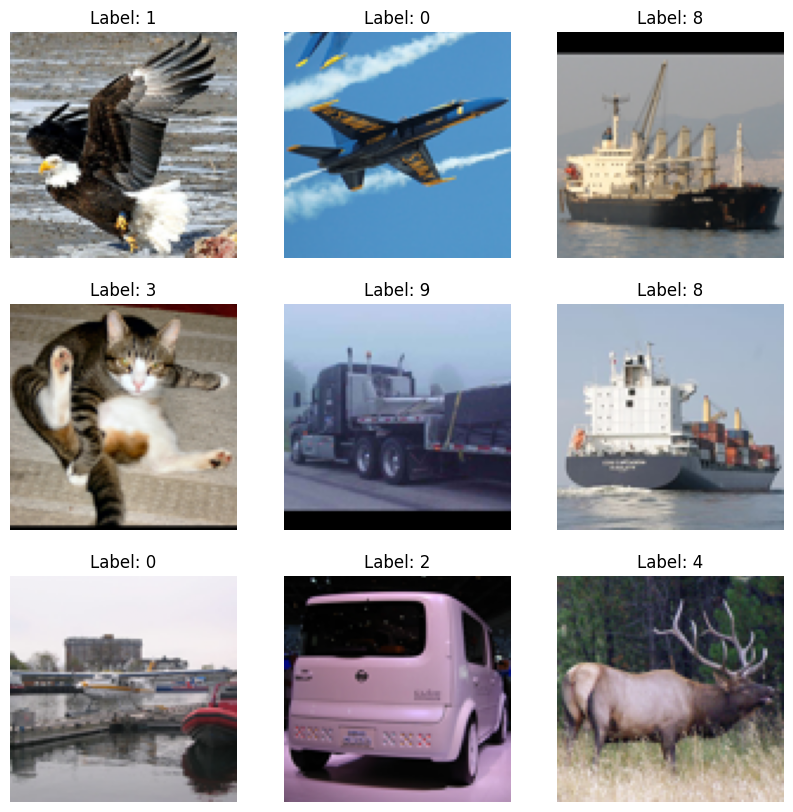

2026-05-16 12:09:00.101773: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [53]:
# Verify that the data is correct
import matplotlib.pyplot as plt

for images, labels in ds_train.take(1):
    print("Shape images:", images.shape)
    print("Shape labels:", labels.shape)
    print("Min/Max images:", tf.reduce_min(images), tf.reduce_max(images))
    print("Sample label:", labels[0])

# Visualize some images and their labels
for images, labels in ds_train.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f"Label: {tf.argmax(labels[i])}")
        plt.axis('off')
    plt.show()

## 2. Baseline

In [53]:
def residual_block(x, filters, kernel_size=3, stride=1):
    shortcut = x

    # First layer of the block
    x = layers.SeparableConv2D(filters, kernel_size, strides=stride, padding='same')(x)
    x = layers.Activation('relu')(x)

    # Second layer of the block
    x = layers.SeparableConv2D(filters, kernel_size, padding='same')(x)

    # If shapes don't match (e.g., due to stride), adjust the shortcut
    if stride > 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), strides=stride, padding='same')(shortcut)

    x = layers.Add()([x, shortcut]) # The Residual Connection
    x = layers.Activation('relu')(x)
    return x

inputs = keras.Input(shape=(96, 96, 3))

# Data Augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1, fill_mode='reflect')(x)
x = layers.RandomZoom(0.1, fill_mode='reflect')(x)

# Entry Flow
x = layers.SeparableConv2D(32, (3, 3), padding='same')(x)
x = layers.Activation('relu')(x)

# Residual Stages (Increasing Depth)
x = residual_block(x, 64, stride=2)
x = residual_block(x, 64)

x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

x = residual_block(x, 256, stride=2)
x = residual_block(x, 256)

x = residual_block(x, 512, stride=2)
x = residual_block(x, 512)

# Classifier Head
x = layers.GlobalAveragePooling2D()(x) # Better than Flatten for deep nets
x = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_tuned = keras.Model(inputs=inputs, outputs=outputs)

model_tuned.compile(optimizer='adam',
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])

model_tuned.summary()

Model: "functional_46"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 96, 96, 3) │          0 │ input_layer_13[0… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 96, 96, 3) │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 96, 96, 3) │          0 │ random_rotation_… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_17 │ (None, 96, 96,    │        155 │ random_zoom_1[0]… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 96, 96,    │          0 │ separable_conv2d… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_18 │ (None, 48, 48,    │      2,400 │ activation_17[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_19 │ (None, 48, 48,    │      4,736 │ activation_18[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 48, 48,    │      2,112 │ activation_17[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 48, 48,    │          0 │ separable_conv2d… │
│                     │ 64)               │            │ conv2d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 48, 48,    │          0 │ add_8[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_20 │ (None, 48, 48,    │      4,736 │ activation_19[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_20       │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_21 │ (None, 48, 48,    │      4,736 │ activation_20[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 48, 48,    │          0 │ separable_conv2d… │
│                     │ 64)               │            │ activation_19[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 48, 48,    │          0 │ add_9[0][0]     

 Total params: 1,561,733 (5.96 MB)

 Trainable params: 1,561,733 (5.96 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_tuned = model_tuned.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])

model_tuned.save("experiments/baseline.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.1482 - loss: 2.2286 - val_accuracy: 0.1800 - val_loss: 2.1480 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.1922 - loss: 2.0724 - val_accuracy: 0.1860 - val_loss: 2.0661 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 115ms/step - accuracy: 0.2377 - loss: 1.9616 - val_accuracy: 0.2520 - val_loss: 1.8718 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.2603 - loss: 1.8608 - val_accuracy: 0.2730 - val_loss: 1.7974 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.2850 - loss: 1.8107 - val_accuracy: 0.2740 - val_loss: 1.8673 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.2982 - loss: 1.7786 - val_accuracy: 0.2940 - val_loss: 1.7725 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 118ms/step - accura

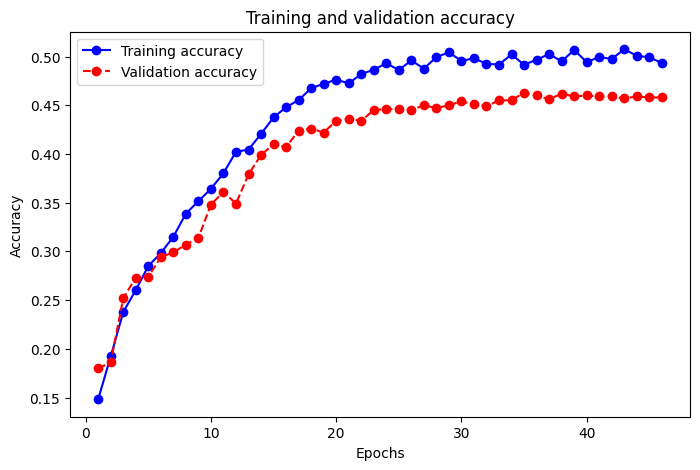

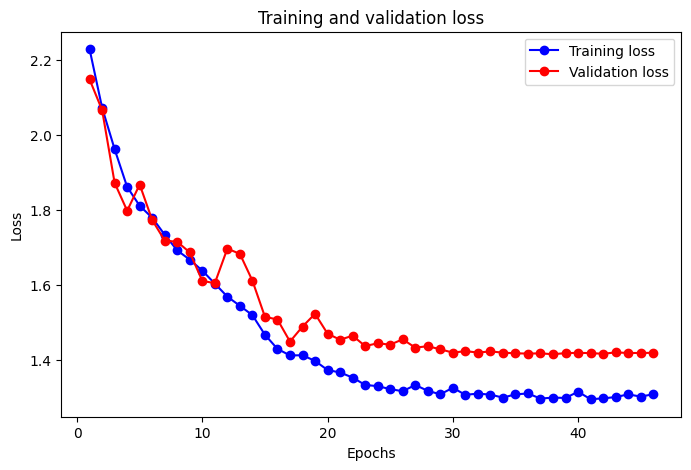

In [55]:
plot(history_tuned)

In [88]:
print("\n--- Test Evaluation ---")
test_loss, test_acc = model_tuned.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.4843 - loss: 1.3806
Test Accuracy: 0.4843 | Test Loss: 1.3806


## 3. Unsupervised Training (Autoencoder)

In [9]:
LATENT_DIM = 1024
encoder_input = layers.Input(shape=(96, 96, 3), name='encoder_input')
e1 = layers.Conv2D(32, 3, activation='relu', padding='same', strides=2, name='e1')(encoder_input)
e2 = layers.Conv2D(64, 3, activation='relu', padding='same', strides=2, name='e2')(e1)
e3 = layers.Conv2D(128, 3, activation='relu', padding='same', strides=2, name='e3')(e2)
e4 = layers.Conv2D(256, 3, activation='relu', padding='same', strides=2, name='e4')(e3)
latent = layers.Flatten(name='flatten')(e4)
latent = layers.Dense(LATENT_DIM, activation='relu', name='latent')(latent)
d = layers.Dense(6 * 6 * 256, activation='relu', name='d_dense')(latent)
d = layers.Reshape((6, 6, 256), name='d_reshape')(d)
d = layers.Conv2DTranspose(128, 3, activation='relu', padding='same', strides=2, name='d_conv1')(d)
d = layers.Concatenate(name='skip1')([d, e3])
d = layers.Conv2DTranspose(64, 3, activation='relu', padding='same', strides=2, name='d_conv2')(d)
d = layers.Concatenate(name='skip2')([d, e2])
d = layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=2, name='d_conv3')(d)
d = layers.Concatenate(name='skip3')([d, e1])
decoder_output = layers.Conv2DTranspose(3, 3, activation='sigmoid', padding='same', strides=2, name='decoder_output')(d)
autoencoder = models.Model(encoder_input, decoder_output, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e1 (Conv2D)         │ (None, 48, 48,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e2 (Conv2D)         │ (None, 24, 24,    │     18,496 │ e1[0][0]          │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e3 (Conv2D)         │ (None, 12, 12,    │     73,856 │ e2[0][0]          │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e4 (Conv2D)         │ (None, 6, 6, 256) │    295,168 │ e3[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 9216)      │          0 │ e4[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent (Dense)      │ (None, 1024)      │  9,438,208 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_dense (Dense)     │ (None, 9216)      │  9,446,400 │ latent[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_reshape (Reshape) │ (None, 6, 6, 256) │          0 │ d_dense[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv1             │ (None, 12, 12,    │    295,040 │ d_reshape[0][0]   │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip1 (Concatenate) │ (None, 12, 12,    │          0 │ d_conv1[0][0],    │
│                     │ 256)              │            │ e3[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv2             │ (None, 24, 24,    │    147,520 │ skip1[0][0]       │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip2 (Concatenate) │ (None, 24, 24,    │          0 │ d_conv2[0][0],    │
│                     │ 128)              │            │ e2[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv3             │ (None, 48, 48,    │     36,896 │ skip2[0][0]       │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip3 (Concatenate) │ (None, 48, 48,    │          0 │ d_conv3[0][0],    │
│                     │ 64)               │            │ e1[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, 96, 96, 3) │      1,731 │ skip3[0][0]       │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,754,211 (75.36 MB)

 Trainable params: 19,754,211 (75.36 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
import keras
from tensorflow import expand_dims

steps_per_epoch = UNS_TRAIN_SIZE // UNS_BATCH_SIZE

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)

history_uns = autoencoder.fit(
    uns_train, 
    epochs=100, 
    steps_per_epoch=steps_per_epoch,
    validation_data=uns_val,
    callbacks=[early_stopping]
)

autoencoder.save("experiments/basic_autoencoder.keras")


Epoch 1/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 182s 253ms/step - loss: 0.0070 - val_loss: 0.0015
Epoch 2/100


/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/DL/dl_p3/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 199s 281ms/step - loss: 0.0011 - val_loss: 9.2592e-04
Epoch 3/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 176s 250ms/step - loss: 7.4404e-04 - val_loss: 5.9170e-04
Epoch 4/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 161s 229ms/step - loss: 5.7567e-04 - val_loss: 4.8330e-04
Epoch 5/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 159s 226ms/step - loss: 4.8574e-04 - val_loss: 4.1451e-04
Epoch 6/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 156s 221ms/step - loss: 4.1633e-04 - val_loss: 3.6527e-04
Epoch 7/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 159s 226ms/step - loss: 3.7727e-04 - val_loss: 3.7767e-04
Epoch 8/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 159s 226ms/step - loss: 3.3361e-04 - val_loss: 3.0597e-04
Epoch 9/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 177s 251ms/step - loss: 3.2068e-04 - val_loss: 3.0890e-04
Epoch 10/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 174s 247ms/step - loss: 2.9066e-04 - val_loss: 2.5718e-04
Epoch 11/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 175s 248ms/step - loss: 2.7664e-04 - val_loss: 2.8709e-04
Epoch 12/100
703/703 ━━━

/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/DL/dl_p3/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 1.1494e-04 - val_loss: 1.1202e-04
Epoch 39/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 147s 208ms/step - loss: 1.1710e-04 - val_loss: 1.5278e-04
Epoch 40/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 149s 210ms/step - loss: 1.1900e-04 - val_loss: 1.0667e-04
Epoch 41/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 146s 207ms/step - loss: 1.1370e-04 - val_loss: 1.2368e-04
Epoch 42/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 149s 211ms/step - loss: 1.1196e-04 - val_loss: 1.1225e-04
Epoch 43/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 148s 210ms/step - loss: 1.0902e-04 - val_loss: 1.1298e-04
Epoch 44/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 157s 224ms/step - loss: 1.0714e-04 - val_loss: 1.0196e-04
Epoch 45/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 158s 224ms/step - loss: 1.0690e-04 - val_loss: 1.0754e-04
Epoch 46/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 158s 224ms/step - loss: 1.0391e-04 - val_loss: 9.6315e-05
Epoch 47/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 206s 293ms/step - loss: 1.0385e-04 - val_loss: 1.2128e-04
Epoch 48/100
703/

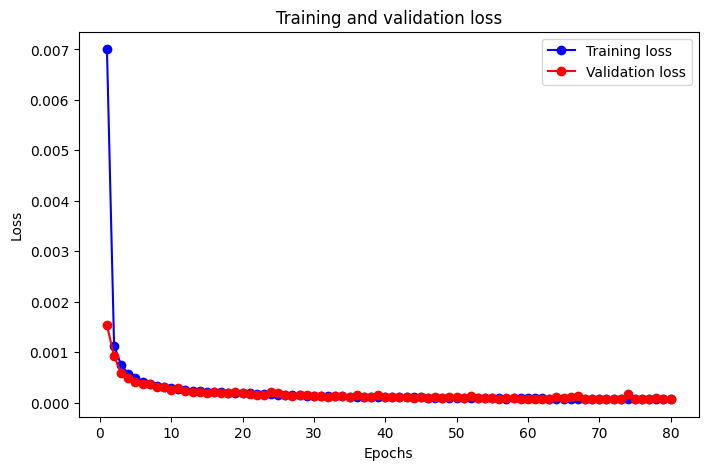

In [11]:
plot(history_uns, only_loss=True)

## 3.1 Verificacion de Reconstrucciones


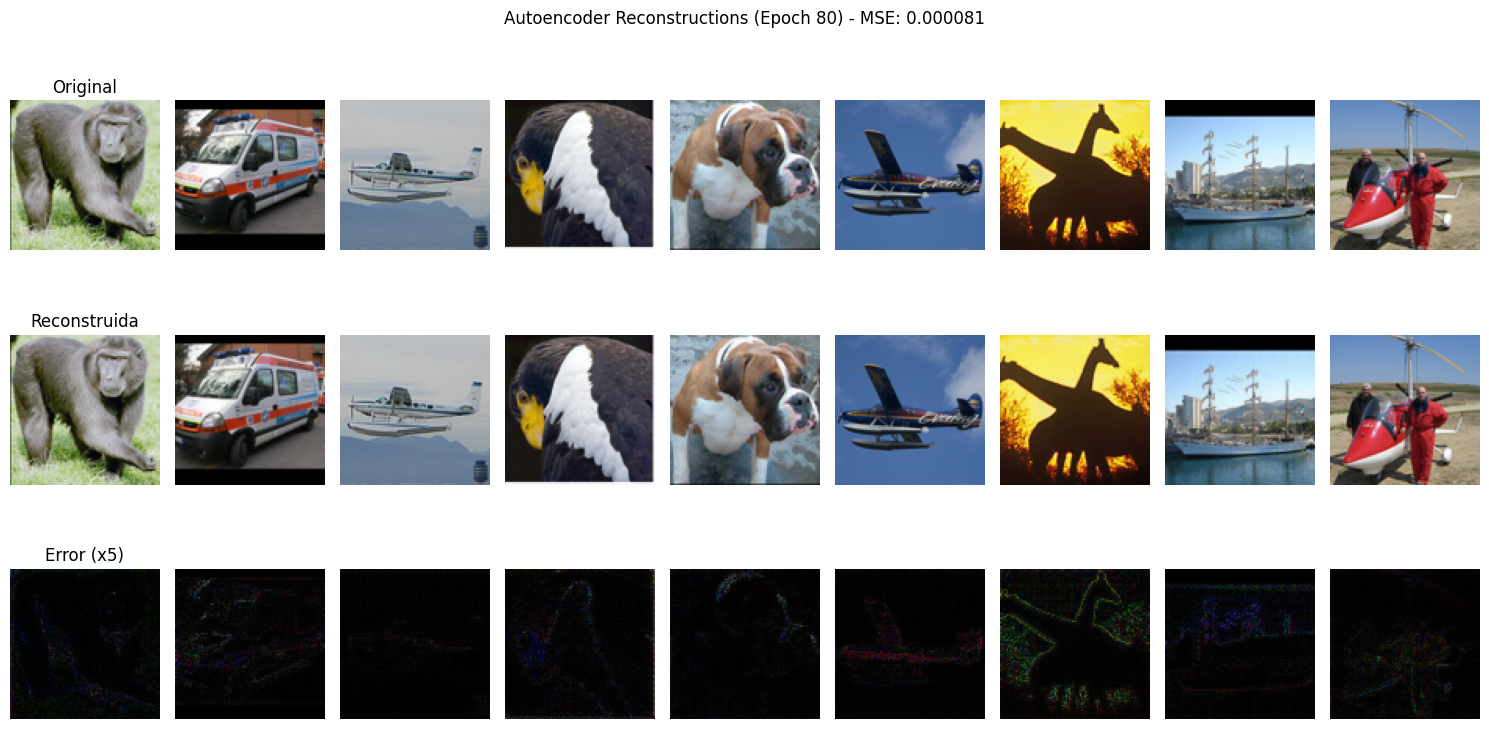

MSE por imagen - min: 0.000011, max: 0.000194, mean: 0.000071


In [12]:
import numpy as np

# Reconstruir imagenes del validation set
n_samples = 9
for images, _ in uns_val.take(1):
    originals = images[:n_samples].numpy()
    reconstructions = autoencoder.predict(originals, verbose=0)
    
    fig, axes = plt.subplots(3, n_samples, figsize=(15, 8))
    for i in range(n_samples):
        axes[0, i].imshow(originals[i])
        axes[0, i].set_title("Original" if i == 0 else "")
        axes[0, i].axis("off")
        
        axes[1, i].imshow(reconstructions[i])
        axes[1, i].set_title("Reconstruida" if i == 0 else "")
        axes[1, i].axis("off")
        
        diff = np.abs(originals[i] - reconstructions[i])
        axes[2, i].imshow(diff * 5)
        axes[2, i].set_title("Error (x5)" if i == 0 else "")
        axes[2, i].axis("off")
    
    plt.suptitle(f"Autoencoder Reconstructions (Epoch {len(history_uns.history['loss'])}) - MSE: {history_uns.history['val_loss'][-1]:.6f}")
    plt.tight_layout()
    plt.show()
    
    mse_per_image = np.mean((originals - reconstructions) ** 2, axis=(1, 2, 3))
    print(f"MSE por imagen - min: {mse_per_image.min():.6f}, max: {mse_per_image.max():.6f}, mean: {mse_per_image.mean():.6f}")
    break


## 4. Latent Space Classification

### 4.1 Approach 1: Using Decoder's Latent Output

In [28]:
import keras
from keras import layers, models

# Get the pretrained encoder - SIMPLER
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")
encoder_input = autoencoder.input   # input del modelo completo
latent_output = autoencoder.get_layer('latent').output
pretrained_encoder = models.Model(inputs=encoder_input, outputs=latent_output)
pretrained_encoder.trainable = False

# Build the new classifier
inputs = layers.Input(shape=(96, 96, 3))
x = pretrained_encoder(inputs)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier = models.Model(inputs=inputs, outputs=outputs, name="latent_classifier")

classifier.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier.summary()

Model: "latent_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_4 (Functional)       │ (None, 1024)           │     9,826,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,091,594 (38.50 MB)

 Trainable params: 264,970 (1.01 MB)

 Non-trainable params: 9,826,624 (37.49 MB)

In [29]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_classifier = classifier.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])

classifier.save("experiments/latent_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.1717 - loss: 41.6144 - val_accuracy: 0.2850 - val_loss: 9.7218 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.1912 - loss: 37.3338 - val_accuracy: 0.2520 - val_loss: 14.7983 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.2065 - loss: 32.5950 - val_accuracy: 0.2610 - val_loss: 11.6787 - learning_rate: 0.0010
Epoch 4/100
123/125 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2124 - loss: 27.1074
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.2077 - loss: 26.6263 - val_accuracy: 0.2670 - val_loss: 10.7796 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.2130 - loss: 21.9896 - val_accuracy: 0.3220 - val_loss: 6.3942 - learning_rate: 3.0000e-04
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy:

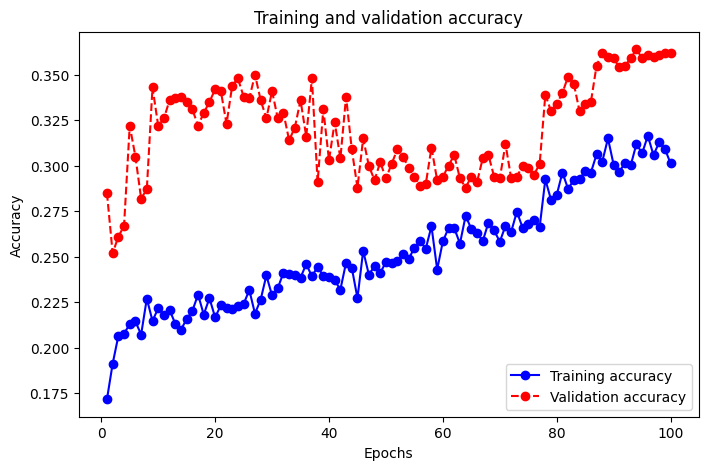

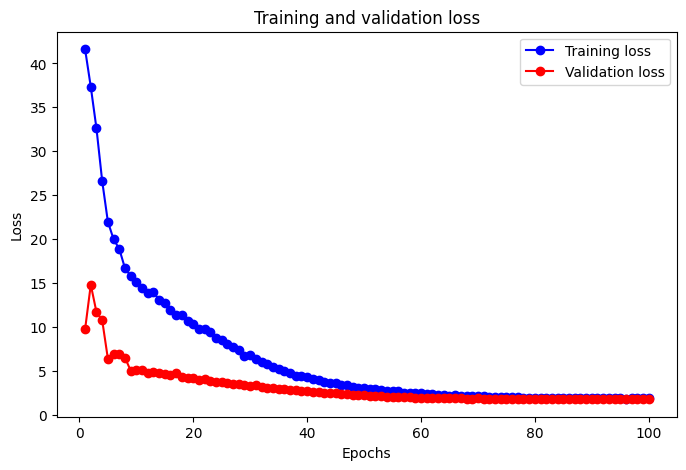

In [30]:
plot(history_classifier)

In [31]:
print("\n--- Test Evaluation ---")
test_loss, test_acc = classifier.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.3611 - loss: 1.7345
Test Accuracy: 0.3611 | Test Loss: 1.7345


## 4.2 Approach 2: Using Intermediate Feature Maps

In [24]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e4 = models.Model(inputs=inputs, outputs=outputs, name="e4_feature_classifier")

classifier_e4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e4.summary()

Model: "e4_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_3 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [25]:
# Train the e4-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e4 = classifier_e4.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e4.save("experiments/e4_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.2192 - loss: 2.3927 - val_accuracy: 0.2360 - val_loss: 2.1648 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.2315 - loss: 2.1654 - val_accuracy: 0.2740 - val_loss: 1.9632 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.2495 - loss: 2.0596 - val_accuracy: 0.2820 - val_loss: 1.9416 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.2607 - loss: 1.9836 - val_accuracy: 0.2980 - val_loss: 1.9027 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.2848 - loss: 1.9446 - val_accuracy: 0.3130 - val_loss: 1.8071 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.2945 - loss: 1.9026 - val_accuracy: 0.3250 - val_loss: 1.7935 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.3045 - l

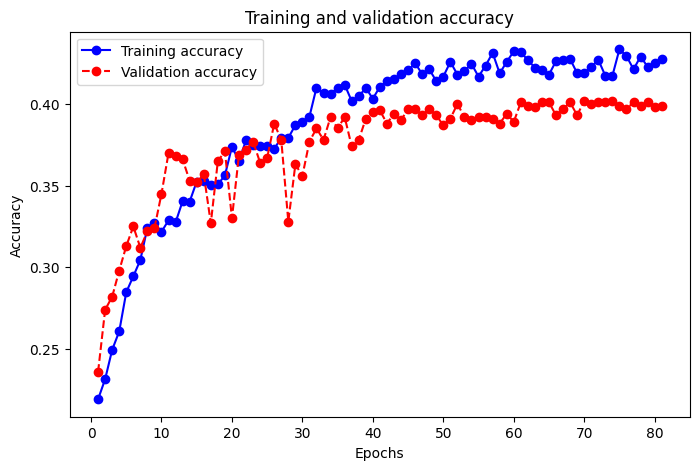

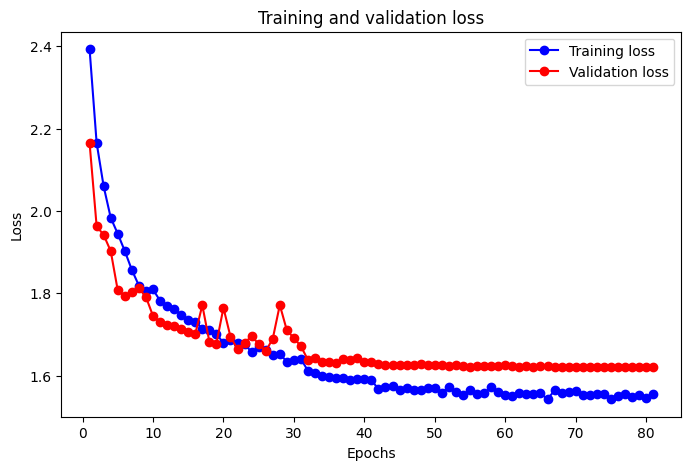

In [26]:
plot(history_e4)

In [27]:
print("\n--- E4 Classifier Test Evaluation ---")
test_loss_e4, test_acc_e4 = classifier_e4.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e4:.4f} | Test Loss: {test_loss_e4:.4f}")


--- E4 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.4144 - loss: 1.5797
Test Accuracy: 0.4144 | Test Loss: 1.5797


### 4.3 Approach 3: Data augmentation

In [ ]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1, fill_mode='reflect')(x)
x = layers.RandomZoom(0.1, fill_mode='reflect')(x)

x = feature_extractor(x)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e5 = models.Model(inputs=inputs, outputs=outputs, name="e5_feature_classifier")

classifier_e5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e5.summary()

Model: "e5_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_1 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [ ]:
# Train the e5-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e5 = classifier_e5.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e5.save("experiments/e5_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.2153 - loss: 2.4065 - val_accuracy: 0.2480 - val_loss: 2.1067 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2520 - loss: 2.1399 - val_accuracy: 0.2550 - val_loss: 2.0226 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2713 - loss: 2.0449 - val_accuracy: 0.2930 - val_loss: 1.8647 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2695 - loss: 1.9772 - val_accuracy: 0.2990 - val_loss: 1.8620 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2880 - loss: 1.9303 - val_accuracy: 0.2750 - val_loss: 1.9072 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3015 - loss: 1.8945 - val_accuracy: 0.2730 - val_loss: 1.9040 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.3047 - l

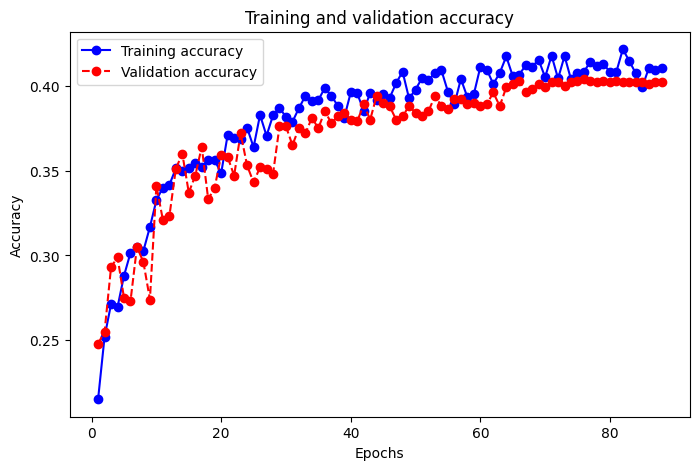

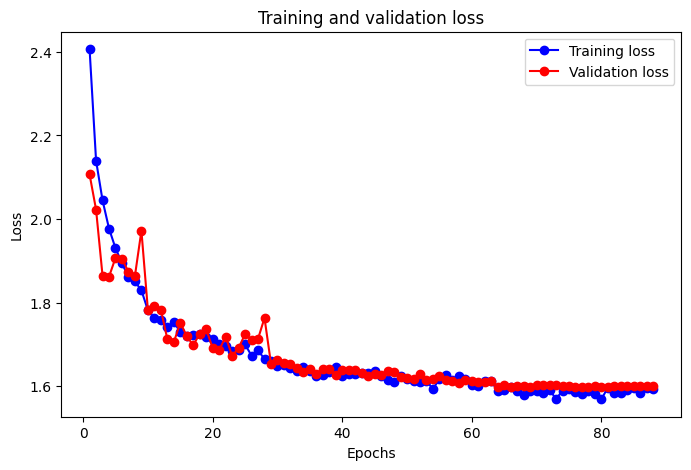

In [ ]:
plot(history_e5)

In [ ]:
print("\n--- E5 Classifier Test Evaluation ---")
test_loss_e5, test_acc_e5 = classifier_e5.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e5:.4f} | Test Loss: {test_loss_e5:.4f}")


--- E5 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4151 - loss: 1.5790
Test Accuracy: 0.4151 | Test Loss: 1.5790


## 4.4 Approach 4: Using L1

In [ ]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l1(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l1(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e6 = models.Model(inputs=inputs, outputs=outputs, name="e6_feature_classifier")

classifier_e6.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e6.summary()

Model: "e6_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_7 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [ ]:
# Train the e6-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e6 = classifier_e6.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e6.save("experiments/e6_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2153 - loss: 2.8618 - val_accuracy: 0.2360 - val_loss: 2.6847 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2492 - loss: 2.5163 - val_accuracy: 0.2650 - val_loss: 2.3973 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2693 - loss: 2.4198 - val_accuracy: 0.2760 - val_loss: 2.2456 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2808 - loss: 2.3455 - val_accuracy: 0.3120 - val_loss: 2.2136 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3000 - loss: 2.2571 - val_accuracy: 0.3050 - val_loss: 2.1895 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3120 - loss: 2.2113 - val_accuracy: 0.3220 - val_loss: 2.1351 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3262 - loss: 2.

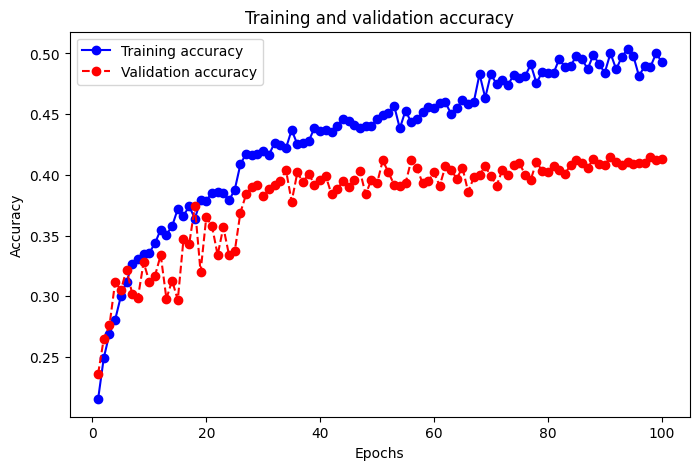

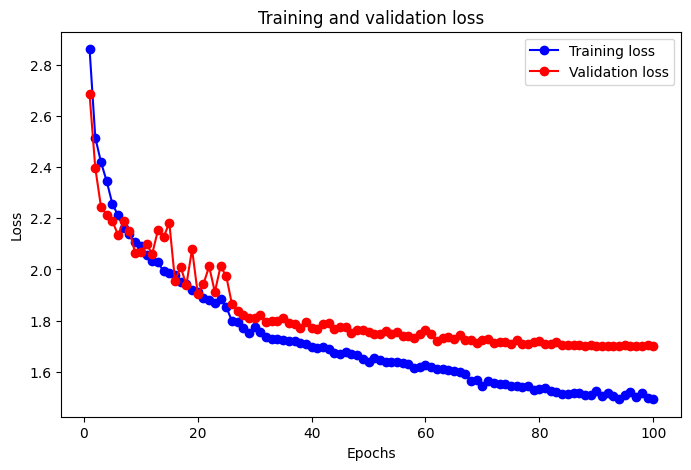

In [ ]:
plot(history_e6)

In [ ]:
print("\n--- E6 Classifier Test Evaluation ---")
test_loss_e6, test_acc_e6 = classifier_e6.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e6:.4f} | Test Loss: {test_loss_e6:.4f}")


--- E6 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4442 - loss: 1.6588
Test Accuracy: 0.4442 | Test Loss: 1.6588


## 4.5 Approach 5: Using L2

In [ ]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e7 = models.Model(inputs=inputs, outputs=outputs, name="e7_feature_classifier")

classifier_e7.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e7.summary()

Model: "e7_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_8 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_11     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [ ]:
# Train the e7-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e7 = classifier_e7.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e7.save("experiments/e7_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2157 - loss: 2.4536 - val_accuracy: 0.2220 - val_loss: 2.1466 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2467 - loss: 2.1577 - val_accuracy: 0.2660 - val_loss: 1.9661 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2688 - loss: 2.0440 - val_accuracy: 0.2530 - val_loss: 2.0084 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2860 - loss: 1.9942 - val_accuracy: 0.2850 - val_loss: 1.9029 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3007 - loss: 1.9248 - val_accuracy: 0.2900 - val_loss: 1.8944 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3083 - loss: 1.8984 - val_accuracy: 0.3080 - val_loss: 1.8275 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3010 - loss: 1.

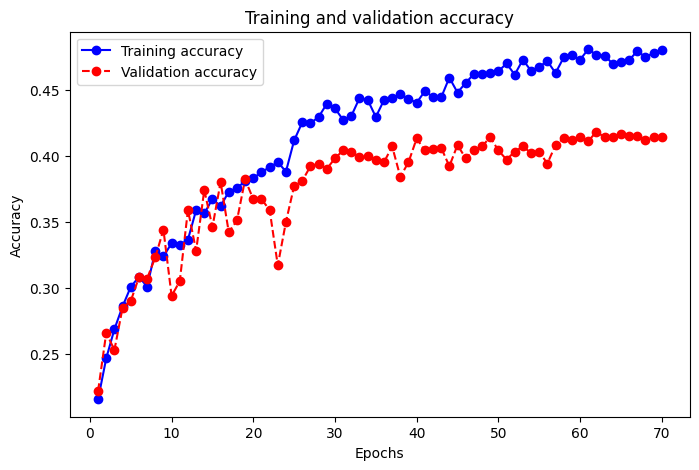

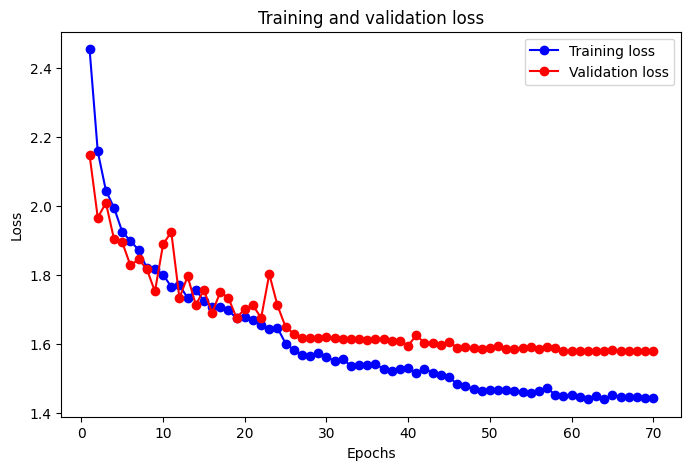

In [ ]:
plot(history_e7)

In [ ]:
print("\n--- E7 Classifier Test Evaluation ---")
test_loss_e7, test_acc_e7 = classifier_e7.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e7:.4f} | Test Loss: {test_loss_e7:.4f}")


--- E7 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4353 - loss: 1.5525
Test Accuracy: 0.4353 | Test Loss: 1.5525


## 5. Fine-Tuning

In [76]:
# ============================================================
# FINE-TUNING: Experiment with partial or full encoder fine-tuning
# Using approach 2: e4 feature extractor + classification head
# ============================================================

import keras
from keras import layers, models
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
import numpy as np

# Load pretrained autoencoder
def build_classifier_with_trainable_encoder(autoencoder, trainable_layers, name_suffix):
    """
    Build a classifier with trainable encoder layers.
    
    Args:
        autoencoder: pretrained autoencoder model
        trainable_layers: list of layer names to unfreeze (e.g., ['e4'] or ['e3', 'e4'])
        name_suffix: suffix for model name
    """
    encoder_input = autoencoder.input
    e4_output = autoencoder.get_layer('e4').output
    feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
    
    for layer in feature_extractor.layers:
        layer.trainable = layer.name in trainable_layers
    
    inputs = layers.Input(shape=(96, 96, 3))
    x = feature_extractor(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation='softmax')(x)
    classifier = models.Model(inputs=inputs, outputs=outputs, name=f"finetune_{name_suffix}")
    
    return classifier, feature_extractor


def count_trainable_params(model):
    trainable = sum([w.numpy().size for w in model.trainable_weights])
    non_trainable = sum([w.numpy().size for w in model.non_trainable_weights])
    return trainable, non_trainable


print("="*60)
print("FINE-TUNING EXPERIMENTS")
print("="*60)
print("\nBaseline: Frozen encoder (from Section 4 approach 2)")
print("Expected val accuracy: ~38-40% with frozen encoder\n")

FINE-TUNING EXPERIMENTS

Baseline: Frozen encoder (from Section 4 approach 2)
Expected val accuracy: ~38-40% with frozen encoder



## Experiment 1: Partial Fine-tuning (Last Block - e4 only)

In [91]:
# Experiment 1: Unfreeze only the last encoder block (e4)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp1, fexp1 = build_classifier_with_trainable_encoder(
    autoencoder, 
    trainable_layers=['e4'],
    name_suffix='e4_only'
)

trainable, non_trainable = count_trainable_params(classifier_exp1)
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e4 (last encoder block)")

classifier_exp1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp1.summary()


Trainable params: 395,914 (0.40M)
Non-trainable params: 94,016 (0.09M)
Trainable layers: e4 (last encoder block)


Model: "finetune_e4_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_19 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_16 (Functional)      │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_19     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_57 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_38          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_58 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_39          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_59 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 395,914 (1.51 MB)

 Non-trainable params: 94,016 (367.25 KB)

In [78]:
# Train Experiment 1
reduce_lr_exp1 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop_exp1 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 1: Fine-tuning e4 only...")
history_exp1 = classifier_exp1.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp1, early_stop_exp1],
    verbose=1
)

print("\n" + "="*60)
print("EXPERIMENT 1 RESULTS - Fine-tuning e4 only")
print("="*60)
print(f"Best val accuracy: {max(history_exp1.history['val_accuracy']):.4f}")
print(f"Final train accuracy: {history_exp1.history['accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history_exp1.history['val_accuracy'][-1]:.4f}")
print(f"Total epochs trained: {len(history_exp1.history['loss'])}")

Training Experiment 1: Fine-tuning e4 only...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.1893 - loss: 2.6531 - val_accuracy: 0.1630 - val_loss: 2.4582 - learning_rate: 1.0000e-04
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2300 - loss: 2.3933 - val_accuracy: 0.2360 - val_loss: 2.1196 - learning_rate: 1.0000e-04
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2303 - loss: 2.3094 - val_accuracy: 0.2510 - val_loss: 2.1552 - learning_rate: 1.0000e-04
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2550 - loss: 2.2113 - val_accuracy: 0.2740 - val_loss: 2.0532 - learning_rate: 1.0000e-04
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2648 - loss: 2.1726 - val_accuracy: 0.2230 - val_loss: 2.3059 - learning_rate: 1.0000e-04
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2600 - loss: 2.1422 - val_accuracy: 0.2400 - val_loss: 2.2959 - learning_rate: 1.0000e-04
Epoch 

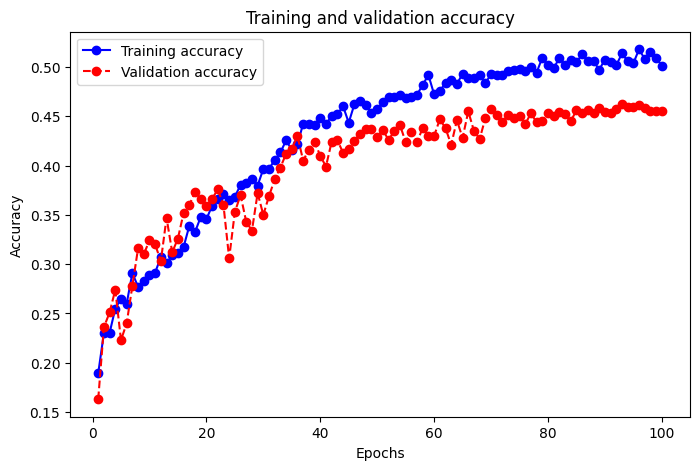

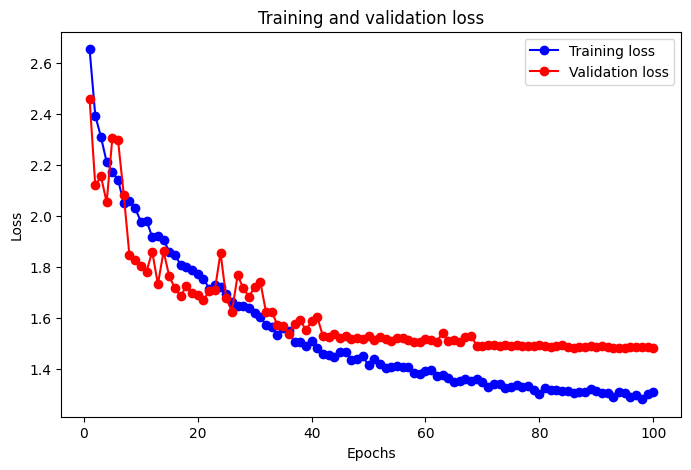

In [79]:
# Plot Experiment 1 learning curves
plot(history_exp1)

In [80]:
classifier_exp1.save("experiments/finetune_e4_only.keras")

## Experiment 2: Partial Fine-tuning (Last 2 Blocks - e3 + e4)

In [92]:
# Experiment 2: Unfreeze last 2 encoder blocks (e3 + e4)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp2, fexp2 = build_classifier_with_trainable_encoder(
    autoencoder, 
    trainable_layers=['e3', 'e4'],
    name_suffix='e3_e4'
)

trainable, non_trainable = count_trainable_params(classifier_exp2)
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e3, e4 (last 2 encoder blocks)")

classifier_exp2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp2.summary()


Trainable params: 469,770 (0.47M)
Non-trainable params: 20,160 (0.02M)
Trainable layers: e3, e4 (last 2 encoder blocks)


Model: "finetune_e3_e4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_20 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_17 (Functional)      │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_20     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 469,770 (1.79 MB)

 Non-trainable params: 20,160 (78.75 KB)

In [93]:
# Train Experiment 2
reduce_lr_exp2 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop_exp2 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 2: Fine-tuning e3 + e4...")
history_exp2 = classifier_exp2.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp2, early_stop_exp2],
    verbose=1
)

print("\n" + "="*60)
print("EXPERIMENT 2 RESULTS - Fine-tuning e3 + e4")
print("="*60)
print(f"Best val accuracy: {max(history_exp2.history['val_accuracy']):.4f}")
print(f"Final train accuracy: {history_exp2.history['accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history_exp2.history['val_accuracy'][-1]:.4f}")
print(f"Total epochs trained: {len(history_exp2.history['loss'])}")

Training Experiment 2: Fine-tuning e3 + e4...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.1725 - loss: 2.7094 - val_accuracy: 0.1730 - val_loss: 2.1434 - learning_rate: 1.0000e-04
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2132 - loss: 2.4054 - val_accuracy: 0.2320 - val_loss: 2.1878 - learning_rate: 1.0000e-04
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2422 - loss: 2.2837 - val_accuracy: 0.2440 - val_loss: 2.0846 - learning_rate: 1.0000e-04
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2548 - loss: 2.1885 - val_accuracy: 0.2870 - val_loss: 1.9008 - learning_rate: 1.0000e-04
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2550 - loss: 2.1584 - val_accuracy: 0.2500 - val_loss: 2.2113 - learning_rate: 1.0000e-04
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.2878 - loss: 2.0686 - val_accuracy: 0.2670 - val_loss: 1.9855 - learning_rate: 1.0000e-04
Epoch 

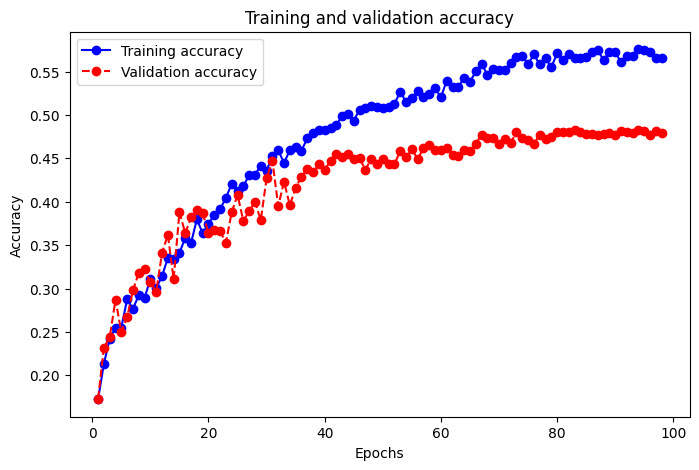

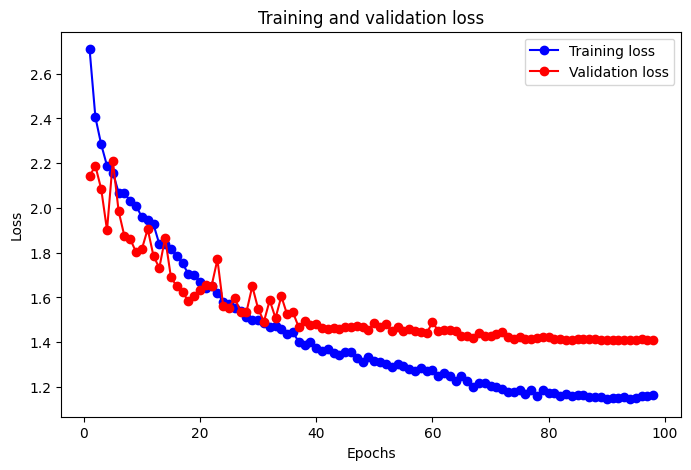

In [94]:
# Plot Experiment 2 learning curves
plot(history_exp2)

In [95]:
classifier_exp2.save("experiments/finetune_e3_e4_classifier.keras")

## Experiment 3: Full Fine-tuning (All Encoder Blocks)

In [86]:
# Experiment 3: Unfreeze entire encoder (full fine-tuning)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp3, fexp3 = build_classifier_with_trainable_encoder(
    autoencoder, 
    trainable_layers=['e1', 'e2', 'e3', 'e4'],
    name_suffix='full_encoder'
)

trainable, non_trainable = count_trainable_params(classifier_exp3)
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e1, e2, e3, e4 (all encoder blocks)")

# Use lower learning rate for full fine-tuning
classifier_exp3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp3.summary()


Trainable params: 489,162 (0.49M)
Non-trainable params: 768 (0.00M)
Trainable layers: e1, e2, e3, e4 (all encoder blocks)


Model: "finetune_full_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_15 (Functional)      │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_18     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_36          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_37          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 489,162 (1.87 MB)

 Non-trainable params: 768 (3.00 KB)

In [87]:
# Train Experiment 3
reduce_lr_exp3 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-7,
    verbose=1
)

early_stop_exp3 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 3: Full encoder fine-tuning...")
history_exp3 = classifier_exp3.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp3, early_stop_exp3],
    verbose=1
)

print("\n" + "="*60)
print("EXPERIMENT 3 RESULTS - Full encoder fine-tuning")
print("="*60)
print(f"Best val accuracy: {max(history_exp3.history['val_accuracy']):.4f}")
print(f"Final train accuracy: {history_exp3.history['accuracy'][-1]:.4f}")
print(f"Final val accuracy: {history_exp3.history['val_accuracy'][-1]:.4f}")
print(f"Total epochs trained: {len(history_exp3.history['loss'])}")

Training Experiment 3: Full encoder fine-tuning...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.1500 - loss: 2.7837 - val_accuracy: 0.2390 - val_loss: 2.1871 - learning_rate: 5.0000e-05
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.2200 - loss: 2.4526 - val_accuracy: 0.2410 - val_loss: 2.0877 - learning_rate: 5.0000e-05
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.2288 - loss: 2.3583 - val_accuracy: 0.2450 - val_loss: 2.0361 - learning_rate: 5.0000e-05
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.2482 - loss: 2.3081 - val_accuracy: 0.2650 - val_loss: 2.0616 - learning_rate: 5.0000e-05
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.2490 - loss: 2.2734 - val_accuracy: 0.2710 - val_loss: 2.1109 - learning_rate: 5.0000e-05
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.2525 - loss: 2.2222 - val_accuracy: 0.2790 - val_loss: 1.9421 - learning_rate: 5.0000e-05
E

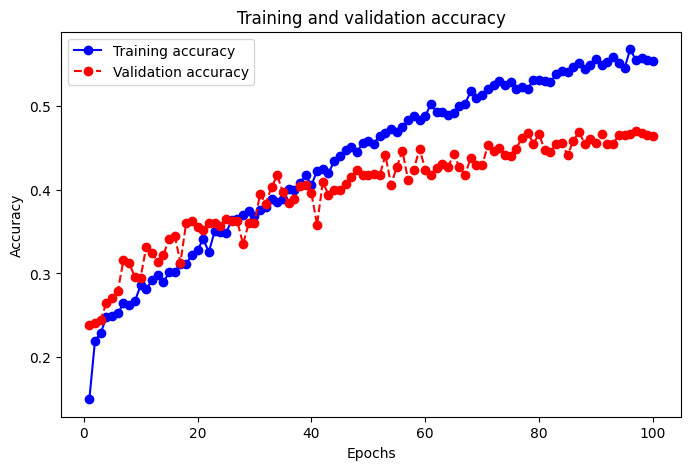

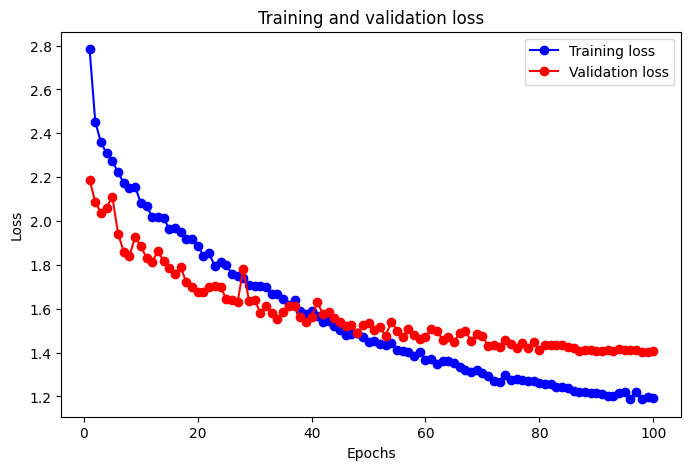

In [88]:
# Plot Experiment 3 learning curves
plot(history_exp3)

In [89]:
classifier_exp3.save("experiments/finetune_full_encoder_classifier.keras")

## Summary: Comparison of Fine-tuning Approaches

In [96]:
# Summary comparison
print("Fine-tuning Experiments Comparison")
print(f"\n{'Experiment':<35} {'Best Val Acc':<15} {'Final Val Acc':<15}")
print("-"*70)
print(f"{'1. Frozen encoder (baseline)':<35} {'~0.38-0.40':<15} {'-':<15}")
print(f"{'2. Fine-tune e4 only':<35} {max(history_exp1.history['val_accuracy']):.4f}{'':<10} {history_exp1.history['val_accuracy'][-1]:.4f}")
print(f"{'3. Fine-tune e3 + e4':<35} {max(history_exp2.history['val_accuracy']):.4f}{'':<10} {history_exp2.history['val_accuracy'][-1]:.4f}")
print(f"{'4. Full encoder fine-tune':<35} {max(history_exp3.history['val_accuracy']):.4f}{'':<10} {history_exp3.history['val_accuracy'][-1]:.4f}")
print("-"*70)

# Evaluate on test set with best models
print("\nTest Set Evaluation:")
print("-"*50)

classifier_exp1 = keras.models.load_model("experiments/finetune_e4_only.keras")
classifier_exp2 = keras.models.load_model("experiments/finetune_e3_e4_classifier.keras")
classifier_exp3 = keras.models.load_model("experiments/finetune_full_encoder_classifier.keras")

test_results = {}
for name, model, _ in [
    ('Exp1: e4 only', classifier_exp1, history_exp1),
    ('Exp2: e3+e4', classifier_exp2, history_exp2),
    ('Exp3: Full encoder', classifier_exp3, history_exp3)
]:
    test_loss, test_acc = model.evaluate(ds_test, verbose=0)
    test_results[name] = test_acc
    print(f"{name}: Test accuracy = {test_acc:.4f}")

print("\n" + "="*70)
print("Best approach:", max(test_results, key=test_results.get))
print("="*70)

Fine-tuning Experiments Comparison

Experiment                          Best Val Acc    Final Val Acc  
----------------------------------------------------------------------
1. Frozen encoder (baseline)        ~0.38-0.40      -              
2. Fine-tune e4 only                0.4620           0.4550
3. Fine-tune e3 + e4                0.4830           0.4790
4. Full encoder fine-tune           0.4700           0.4640
----------------------------------------------------------------------

Test Set Evaluation:
--------------------------------------------------
Exp1: e4 only: Test accuracy = 0.4620
Exp2: e3+e4: Test accuracy = 0.4909
Exp3: Full encoder: Test accuracy = 0.4893

Best approach: Exp2: e3+e4
